## Imports


In [1]:
# -*- coding: utf-8 -*-
"""
Image Classification with E-ELAN Lite (PyTorch)
- EELANLite block (group conv -> channel shuffle -> concat -> 1x1 fuse + residual)
- CNN+Pooling backbone + EELANLite + GAP + Linear
- ImageFolder dataloader (train/val; if val missing, auto-split with independent transforms)
- Train/Validate with AMP (CUDA), cosine lr schedule
- Save best checkpoint; Predict image/folder top-k
"""

import os
import math
import time
import copy
from pathlib import Path
from typing import List, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from PIL import Image
import numpy as np



## Configuration


In [2]:
# -------------------------------
# CONFIG
# -------------------------------
CFG = {
    "data_root": "D:/SPCV/miniproject/datasets/classification",          # cat, dog, panda crops
    "train_dir": "train",
    "val_dir": "valid",
    "test_dir": "test",
    "auto_split_val_ratio": 0.1,

    "img_size": 224,
    "num_workers": 0,

    "epochs": 40,
    "batch_size": 32,
    "lr": 1e-3,
    "weight_decay": 0.01,
    "label_smoothing": 0.05,
    "amp": True,   # CUDA-only

    "C_stem": 48,
    "C_stage": 128,
    "m": 2.0,
    "g": 2,

    "use_cosine": True,
    "min_lr_scale": 0.05,

    "out_dir": "D:/SPCV/miniproject/classification/outputs/cls_eelan_improved",
    "best_ckpt": "best.pt",
    "topk": 5,

    "predict_path": None,  # set path to image or folder if you want to predict after training
    "seed": 42,
}



## Utilities and basic layers


In [ ]:
# -------------------------------
# Utils
# -------------------------------
def set_seed(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

class ConvBNAct(nn.Module):
    def __init__(self, c_in, c_out, k=3, s=1, p=None, g=1, act=True):
        super().__init__()
        if p is None:
            p = (k - 1) // 2
        self.conv = nn.Conv2d(c_in, c_out, k, s, p, groups=g, bias=False)
        self.bn   = nn.BatchNorm2d(c_out)
        self.act  = nn.SiLU(inplace=True) if act else nn.Identity()
    def forward(self, x):
        return self.act(self.bn(self.conv(x)))

def channel_shuffle(x: torch.Tensor, groups: int) -> torch.Tensor:
    if groups <= 1:
        return x
    b, c, h, w = x.shape
    assert c % groups == 0, "channels must be divisible by groups"
    x = x.view(b, groups, c // groups, h, w)
    x = x.transpose(1, 2).contiguous()
    x = x.view(b, c, h, w)
    return x



## E-ELAN classifier model


In [4]:
class EELANLite(nn.Module):
    """
    Minimal E-ELAN:
      - 1x1 group conv expand to m*C (groups=g)
      - 4 branches with depths [0,1,2,3] (3x3 group conv)
      - channel shuffle per branch
      - concat -> 1x1 fuse to C_out (default C_in), residual if shapes match
    """
    def __init__(self,
                 C_in: int,
                 C_out: int = None,
                 m: float = 2.0,
                 g: int = 2,
                 branch_depths: List[int] = None,
                 use_skip: bool = True):
        super().__init__()
        assert m >= 1
        self.C_in  = C_in
        self.C_out = C_in if C_out is None else C_out
        self.m     = m
        self.g     = g
        self.use_skip = use_skip and (self.C_out == self.C_in)

        C_exp = int(round(self.m * self.C_in))
        C_exp = max(4*self.g, (C_exp // (4*self.g)) * (4*self.g))  # divisible by 4*g
        self.C_exp = C_exp

        self.expand = ConvBNAct(self.C_in, self.C_exp, k=1, s=1, p=0, g=self.g, act=True)

        self.num_branches = 4
        self.split_ch = self.C_exp // self.num_branches
        assert self.C_exp % self.num_branches == 0

        if branch_depths is None:
            branch_depths = [0, 1, 2, 3]
        self.branch_depths = branch_depths[:self.num_branches]

        branches = []
        for d in self.branch_depths:
            layers = []
            in_ch  = self.split_ch
            for _ in range(d):
                layers.append(ConvBNAct(in_ch, in_ch, k=3, s=1, p=1, g=self.g, act=True))
            branches.append(nn.Sequential(*layers) if layers else nn.Identity())
        self.branches = nn.ModuleList(branches)

        self.fuse = ConvBNAct(self.C_exp, self.C_out, k=1, s=1, p=0, g=1, act=True)

    def forward(self, x):
        identity = x
        y = self.expand(x)
        chunks = torch.chunk(y, self.num_branches, dim=1)
        outs = [br(ch) for br, ch in zip(self.branches, chunks)]
        outs = [channel_shuffle(t, self.g) for t in outs]
        y = torch.cat(outs, dim=1)
        y = self.fuse(y)
        if self.use_skip and y.shape == identity.shape:
            y = y + identity
        return y

class EELANClassifier(nn.Module):
    """
    CNN+Pooling backbone with one EELANLite stage
      Stem:  Conv 3x3 s=2 -> Conv 3x3
      Stage1: MaxPool s=2 -> Conv 3x3
      EELAN stage: EELANLite(C_stage)
      Neck:  Conv 1x1
      Head:  GAP -> Linear(num_classes)
    """
    def __init__(self, num_classes: int,
                 C_in=3, C_stem=32, C_stage=96,
                 m=2.0, g=2, neck_channels=128):
        super().__init__()
        self.stem = nn.Sequential(
            ConvBNAct(C_in, C_stem, k=3, s=2),     # H/2
            ConvBNAct(C_stem, C_stem, k=3, s=1),
        )
        self.stage1 = nn.Sequential(
            nn.MaxPool2d(kernel_size=2, stride=2), # H/4
            ConvBNAct(C_stem, C_stage, k=3, s=1),
        )
        self.eelan = EELANLite(C_stage, C_stage, m=m, g=g, branch_depths=[0,1,2,3], use_skip=True)
        self.neck = ConvBNAct(C_stage, neck_channels, k=1, s=1, p=0, g=1, act=True)
        self.head = nn.Linear(neck_channels, num_classes)

        # ---- FIX: init conv weights with 'relu' gain (PyTorch khÃ´ng há»— trá»£ 'silu' á»Ÿ calculate_gain) ----
        for m_ in self.modules():
            if isinstance(m_, nn.Conv2d):
                nn.init.kaiming_normal_(m_.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m_, nn.BatchNorm2d):
                nn.init.constant_(m_.weight, 1.0)
                nn.init.constant_(m_.bias, 0.0)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.eelan(x)
        x = self.neck(x)
        x = F.adaptive_avg_pool2d(x, output_size=1).squeeze(-1).squeeze(-1)  # (B, C)
        logits = self.head(x)
        return logits



## Transforms and data loaders


In [5]:
# -------------------------------
# Data
# -------------------------------
def build_transforms(img_size=224, is_train=True):
    if is_train:
        return transforms.Compose([
            transforms.Resize((img_size, img_size), interpolation=InterpolationMode.BILINEAR),
            transforms.RandomHorizontalFlip(),
            transforms.ColorJitter(0.2, 0.2, 0.2, 0.1),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485,0.456,0.406],
                                 std=[0.229,0.224,0.225]),
        ])
    else:
        return transforms.Compose([
            transforms.Resize((img_size, img_size), interpolation=InterpolationMode.BILINEAR),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485,0.456,0.406],
                                 std=[0.229,0.224,0.225]),
        ])

def build_dataloaders(cfg):
    train_root = os.path.join(cfg["data_root"], cfg["train_dir"])
    val_root   = os.path.join(cfg["data_root"], cfg["val_dir"])

    if os.path.isdir(val_root) and any(os.scandir(val_root)):
        # explicit train/val
        train_ds = datasets.ImageFolder(train_root, transform=build_transforms(cfg["img_size"], True))
        val_ds   = datasets.ImageFolder(val_root,   transform=build_transforms(cfg["img_size"], False))
    else:
        # ---- FIX: auto-split with independent datasets (avoid shared transform pitfall) ----
        base_train = datasets.ImageFolder(train_root)  # no transform
        n_total = len(base_train)
        n_val = max(1, int(round(n_total * float(cfg["auto_split_val_ratio"]))))
        n_train = n_total - n_val
        # reproducible split
        gen = torch.Generator().manual_seed(CFG["seed"])
        train_idx, val_idx = torch.utils.data.random_split(range(n_total), [n_train, n_val], generator=gen)

        train_ds_full = datasets.ImageFolder(train_root, transform=build_transforms(cfg["img_size"], True))
        val_ds_full   = datasets.ImageFolder(train_root, transform=build_transforms(cfg["img_size"], False))
        train_ds = Subset(train_ds_full, train_idx.indices if hasattr(train_idx, "indices") else train_idx)
        val_ds   = Subset(val_ds_full,   val_idx.indices   if hasattr(val_idx, "indices")   else val_idx)

    # class names from the underlying dataset of train_ds
    class_names = train_ds.dataset.classes if hasattr(train_ds, "dataset") else train_ds.classes

    train_loader = DataLoader(train_ds, batch_size=cfg["batch_size"], shuffle=True,
                              num_workers=cfg["num_workers"], pin_memory=True)
    val_loader   = DataLoader(val_ds, batch_size=cfg["batch_size"], shuffle=False,
                              num_workers=cfg["num_workers"], pin_memory=True)
    return train_loader, val_loader, class_names



## Training and evaluation functions


In [6]:
# -------------------------------
# Train / Eval
# -------------------------------
def accuracy_topk(output, target, topk=(1,)):
    maxk = max(topk)
    batch_size = target.size(0)
    _, pred = output.topk(maxk, dim=1, largest=True, sorted=True)
    pred = pred.t()
    correct = pred.eq(target.view(1, -1).expand_as(pred))
    out = []
    for k in topk:
        correct_k = correct[:k].reshape(-1).float().sum(0, keepdim=True)
        out.append((correct_k * (100.0 / batch_size)).item())
    return out

def train_one_epoch(model, loader, optimizer, scaler, device, epoch, loss_fn):
    model.train()
    running_loss = 0.0
    tot = 0
    top1_sum = 0.0
    for i, (x, y) in enumerate(loader):
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        if scaler is not None:
            with torch.autocast(device_type=device.type, dtype=torch.float16):
                logits = model(x)
                loss = loss_fn(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(x)
            loss = loss_fn(logits, y)
            loss.backward()
            optimizer.step()

        bsz = x.size(0)
        acc1 = accuracy_topk(logits.detach(), y, topk=(1,))[0]
        running_loss += loss.item() * bsz
        top1_sum += acc1 * bsz / 100.0
        tot += bsz

    return running_loss / tot, (top1_sum / tot) * 100.0

@torch.no_grad()
def evaluate(model, loader, device, loss_fn):
    model.eval()
    running_loss = 0.0
    tot = 0
    top1_sum = 0.0
    per_class_correct = None
    per_class_count = None

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        logits = model(x)
        loss = loss_fn(logits, y)

        bsz = x.size(0)
        acc1 = accuracy_topk(logits, y, topk=(1,))[0]
        running_loss += loss.item() * bsz
        top1_sum += acc1 * bsz / 100.0
        tot += bsz

        preds = logits.argmax(dim=1)
        if per_class_correct is None:
            ncls = int(logits.shape[1])
            per_class_correct = torch.zeros(ncls, dtype=torch.long, device=device)
            per_class_count   = torch.zeros(ncls, dtype=torch.long, device=device)
        for t, p in zip(y, preds):
            per_class_count[t] += 1
            per_class_correct[t] += int(t == p)

    avg_loss = running_loss / tot
    top1 = (top1_sum / tot) * 100.0
    if per_class_correct is not None:
        per_class_acc = (per_class_correct.float() / per_class_count.clamp(min=1).float()) * 100.0
        per_class_acc = per_class_acc.cpu().tolist()
    else:
        per_class_acc = None
    return avg_loss, top1, per_class_acc



## Inference functions


In [7]:
# -------------------------------
# Predict
# -------------------------------
@torch.no_grad()
def predict_images(model, device, class_names, path, img_size=224, topk=5):
    if os.path.isdir(path):
        import glob
        files = []
        for ext in ("*.jpg","*.jpeg","*.png","*.bmp","*.webp","*.JPG","*.PNG","*.JPEG"):
            files.extend(glob.glob(os.path.join(path, ext)))
        files = sorted(files)
    else:
        files = [path]

    tfm = build_transforms(img_size, is_train=False)
    results = []
    model.eval()
    for f in files:
        try:
            im = Image.open(f).convert("RGB")
        except Exception as e:
            print(f"[warn] cannot open {f}: {e}")
            continue
        x = tfm(im).unsqueeze(0).to(device)
        logits = model(x)
        prob = torch.softmax(logits, dim=1)[0]
        topv, topi = prob.topk(min(topk, len(class_names)))
        preds = [(class_names[i], float(topv[j].item())) for j, i in enumerate(topi)]
        results.append((f, preds))
    return results

# -------------------------------


## Training main function


In [8]:
# Main
# -------------------------------
def main(cfg):
    set_seed(cfg["seed"])
    os.makedirs(cfg["out_dir"], exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.backends.cudnn.benchmark = True

    print("Building dataloaders...")
    train_loader, val_loader, class_names = build_dataloaders(cfg)
    num_classes = len(class_names)
    print(f"Classes ({num_classes}): {class_names}")

    print("Building model...")
    model = EELANClassifier(
        num_classes=num_classes,
        C_in=3,
        C_stem=cfg["C_stem"],
        C_stage=cfg["C_stage"],
        m=cfg["m"],
        g=cfg["g"],
        neck_channels=128,
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])

    if cfg["use_cosine"]:
        # epoch-wise cosine schedule
        def lr_lambda(ep):
            if cfg["epochs"] <= 1:
                return 1.0
            t = ep / (cfg["epochs"] - 1)
            cos = 0.5 * (1 + math.cos(math.pi * t))
            return cfg["min_lr_scale"] + (1 - cfg["min_lr_scale"]) * cos
        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)
    else:
        scheduler = None

    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"]) if cfg["label_smoothing"] > 0 \
              else nn.CrossEntropyLoss()

    scaler = torch.cuda.amp.GradScaler() if (cfg["amp"] and device.type == "cuda") else None

    best_acc = -1.0
    best_wts = copy.deepcopy(model.state_dict())

    for epoch in range(cfg["epochs"]):
        t0 = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, scaler, device, epoch, loss_fn)
        val_loss, val_acc, per_class_acc = evaluate(model, val_loader, device, loss_fn)

        if scheduler is not None:
            scheduler.step()

        if val_acc > best_acc:
            best_acc = val_acc
            best_wts = copy.deepcopy(model.state_dict())
            torch.save({
                "model": best_wts,
                "classes": class_names,
                "cfg": cfg
            }, os.path.join(cfg["out_dir"], cfg["best_ckpt"]))
        dt = time.time() - t0

        print(f"Epoch {epoch+1:03d}/{cfg['epochs']:03d} | "
              f"train_loss {train_loss:.4f} acc@1 {train_acc:.2f}% | "
              f"val_loss {val_loss:.4f} acc@1 {val_acc:.2f}% | "
              f"time {dt:.1f}s")

        if per_class_acc is not None:
            show = ", ".join([f"{cls}:{acc:.1f}%" for cls, acc in zip(class_names, per_class_acc)])
            print(f"  per-class acc: {show}")

    model.load_state_dict(best_wts)
    print(f"Best val acc@1: {best_acc:.2f}%  | checkpoint: {os.path.join(cfg['out_dir'], cfg['best_ckpt'])}")

    if cfg["predict_path"]:
        print(f"Predicting: {cfg['predict_path']}")
        results = predict_images(model, device, class_names, cfg["predict_path"],
                                 img_size=cfg["img_size"], topk=cfg["topk"])
        for f, preds in results:
            print(f"\n{f}")
            for cls, p in preds:
                print(f"  {cls:>20s}: {p:.4f}")



## Run training


In [9]:
# Original training entry point disabled.
# Use the enhanced training/evaluation cells below.


## Enhanced training with history


In [10]:
# Train once, save history, and save the best checkpoint.
import csv
import json
import matplotlib.pyplot as plt

def train_with_history(cfg):
    set_seed(cfg["seed"])
    os.makedirs(cfg["out_dir"], exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    train_loader, val_loader, class_names = build_dataloaders(cfg)
    model = EELANClassifier(
        num_classes=len(class_names), C_in=3,
        C_stem=cfg["C_stem"], C_stage=cfg["C_stage"],
        m=cfg["m"], g=cfg["g"], neck_channels=128,
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = None
    if cfg["use_cosine"]:
        def lr_lambda(ep):
            if cfg["epochs"] <= 1:
                return 1.0
            t = ep / (cfg["epochs"] - 1)
            return cfg["min_lr_scale"] + (1 - cfg["min_lr_scale"]) * 0.5 * (1 + math.cos(math.pi * t))
        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"]) if cfg["label_smoothing"] > 0 else nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler() if (cfg["amp"] and device.type == "cuda") else None
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_wts = -1.0, copy.deepcopy(model.state_dict())
    for epoch in range(cfg["epochs"]):
        t0 = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, scaler, device, epoch, loss_fn)
        val_loss, val_acc, per_class_acc = evaluate(model, val_loader, device, loss_fn)
        history["train_loss"].append(float(train_loss)); history["val_loss"].append(float(val_loss))
        history["train_acc"].append(float(train_acc)); history["val_acc"].append(float(val_acc))
        if scheduler is not None:
            scheduler.step()
        if val_acc > best_acc:
            best_acc = val_acc; best_wts = copy.deepcopy(model.state_dict())
            torch.save({"model": best_wts, "classes": class_names, "cfg": cfg, "history": history, "best_acc": best_acc}, os.path.join(cfg["out_dir"], cfg["best_ckpt"]))
        print(f"Epoch {epoch+1:03d}/{cfg['epochs']:03d} | train_loss {train_loss:.4f} acc@1 {train_acc:.2f}% | val_loss {val_loss:.4f} acc@1 {val_acc:.2f}% | time {time.time()-t0:.1f}s")
        print("  per-class acc: " + ", ".join(f"{n}:{a:.1f}%" for n,a in zip(class_names, per_class_acc)))
    model.load_state_dict(best_wts)
    history_path=os.path.join(cfg["out_dir"], "history.json")
    Path(history_path).write_text(json.dumps(history, indent=2), encoding="utf-8")
    with open(os.path.join(cfg["out_dir"], "history.csv"), "w", newline="", encoding="utf-8") as f:
        writer=csv.writer(f); writer.writerow(["epoch", "train_loss", "val_loss", "train_acc", "val_acc"])
        for i in range(len(history["train_loss"])):
            writer.writerow([i+1, history["train_loss"][i], history["val_loss"][i], history["train_acc"][i], history["val_acc"][i]])
    return model, device, class_names, history

def plot_training_history(history, out_dir):
    out=Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    epochs=range(1, len(history["train_loss"])+1)
    plt.figure(figsize=(8,5)); plt.plot(epochs, history["train_loss"], label="train"); plt.plot(epochs, history["val_loss"], label="validation"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss curve"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(out/"loss_curve.png", dpi=150); plt.show(); plt.close()
    plt.figure(figsize=(8,5)); plt.plot(epochs, history["train_acc"], label="train"); plt.plot(epochs, history["val_acc"], label="validation"); plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)"); plt.title("Accuracy curve"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(out/"accuracy_curve.png", dpi=150); plt.show(); plt.close()


## Load weights and evaluate the labeled test set


C:\Users\nduc8\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 001/040 | train_loss 0.9634 acc@1 55.23% | val_loss 0.8734 acc@1 65.04% | time 236.4s
  per-class acc: cat:57.4%, dog:49.8%, panda:87.2%
Epoch 002/040 | train_loss 0.9174 acc@1 58.72% | val_loss 0.8856 acc@1 59.71% | time 202.8s
  per-class acc: cat:48.5%, dog:34.2%, panda:95.3%
Epoch 003/040 | train_loss 0.8594 acc@1 62.33% | val_loss 0.8484 acc@1 63.60% | time 212.7s
  per-class acc: cat:87.7%, dog:36.9%, panda:65.1%
Epoch 004/040 | train_loss 0.8139 acc@1 65.43% | val_loss 1.1425 acc@1 41.29% | time 214.3s
  per-class acc: cat:97.4%, dog:22.7%, panda:3.0%
Epoch 005/040 | train_loss 0.7614 acc@1 68.01% | val_loss 0.7384 acc@1 69.06% | time 222.2s
  per-class acc: cat:55.3%, dog:77.8%, panda:74.5%
Epoch 006/040 | train_loss 0.7203 acc@1 70.91% | val_loss 0.6280 acc@1 77.55% | time 211.1s
  per-class acc: cat:78.7%, dog:65.3%, panda:88.1%
Epoch 007/040 | train_loss 0.6747 acc@1 74.21% | val_loss 0.7830 acc@1 69.64% | time 212.3s
  per-class acc: cat:45.5%, dog:66.7%, panda:96.6%


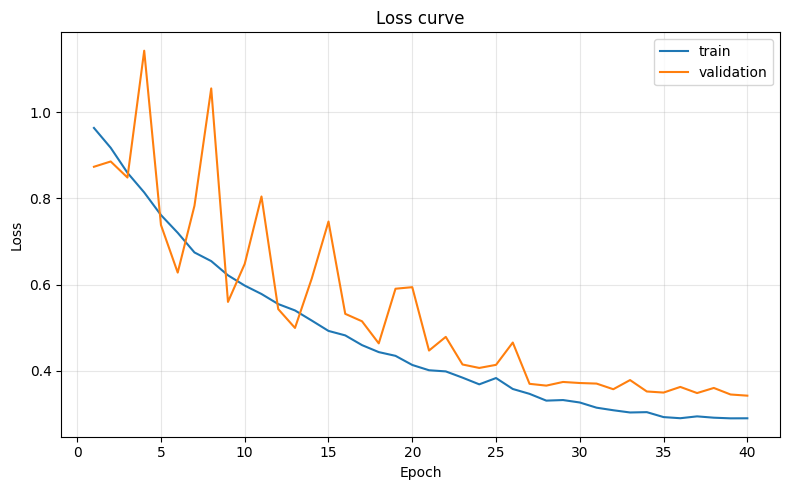

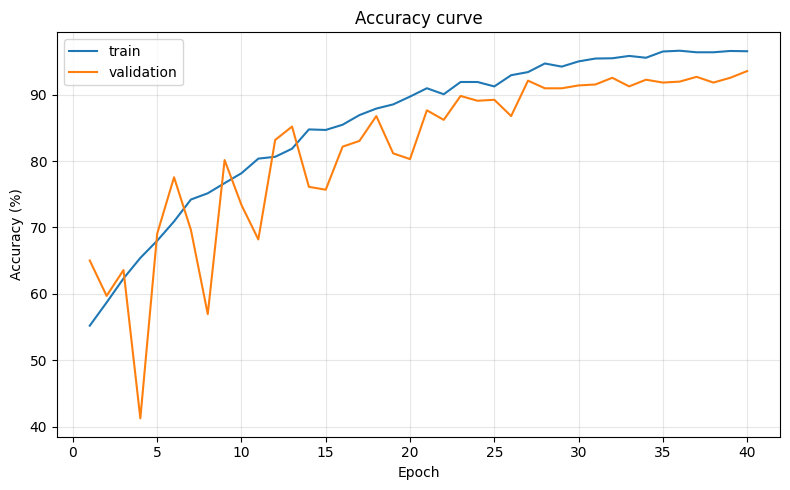

Test accuracy: 91.11%
cat: precision=0.7778, recall=0.9655, f1=0.8615, support=116
dog: precision=0.9718, recall=0.8915, f1=0.9299, support=387
panda: precision=0.8917, recall=0.9224, f1=0.9068, support=116
Confusion matrix (rows=true, columns=predicted):
 [[112   3   1]
 [ 30 345  12]
 [  2   7 107]]
Saved outputs to: D:/SPCV/miniproject/classification/outputs/cls_eelan_improved


In [11]:
# Load best.pt, run folder inference, and calculate precision/recall/F1.
def load_checkpoint_model(weight_path, device=None):
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(weight_path, map_location=device, weights_only=False)
    cfg = checkpoint["cfg"]; class_names = checkpoint["classes"]
    model = EELANClassifier(num_classes=len(class_names), C_in=3, C_stem=cfg["C_stem"], C_stage=cfg["C_stage"], m=cfg["m"], g=cfg["g"], neck_channels=128).to(device)
    model.load_state_dict(checkpoint["model"]); model.eval()
    return model, device, class_names, checkpoint

def evaluate_test_set(model, device, class_names, cfg):
    test_dir = cfg.get("test_dir")
    if not test_dir:
        raise ValueError("Set CFG['test_dir'] to a labeled test folder before evaluating the test set.")
    test_root=Path(cfg["data_root"])/test_dir
    ds=datasets.ImageFolder(test_root, transform=build_transforms(cfg["img_size"], False))
    loader=DataLoader(ds, batch_size=cfg["batch_size"], shuffle=False, num_workers=cfg["num_workers"], pin_memory=(device.type=="cuda"))
    cm=torch.zeros((len(class_names), len(class_names)), dtype=torch.long)
    rows=[]
    with torch.no_grad():
        for images, targets in loader:
            probs=torch.softmax(model(images.to(device)), dim=1).cpu(); preds=probs.argmax(1)
            for target,pred,prob in zip(targets.tolist(), preds.tolist(), probs):
                cm[target,pred]+=1; rows.append({"true_class":class_names[target], "predicted_class":class_names[pred], "confidence":float(prob[pred]), "correct":target==pred})
    metrics=[]
    for i,name in enumerate(class_names):
        tp=int(cm[i,i]); fp=int(cm[:,i].sum()-tp); fn=int(cm[i,:].sum()-tp)
        precision=tp/(tp+fp) if tp+fp else 0.0; recall=tp/(tp+fn) if tp+fn else 0.0; f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
        metrics.append({"class":name,"precision":precision,"recall":recall,"f1":f1,"support":int(cm[i,:].sum())})
    accuracy=float(cm.diag().sum()/cm.sum()) if cm.sum() else 0.0
    print(f"Test accuracy: {accuracy*100:.2f}%")
    for m in metrics: print(f"{m['class']}: precision={m['precision']:.4f}, recall={m['recall']:.4f}, f1={m['f1']:.4f}, support={m['support']}")
    print("Confusion matrix (rows=true, columns=predicted):\n", cm.numpy())
    out=Path(cfg["out_dir"]); out.mkdir(parents=True, exist_ok=True)
    with open(out/"test_predictions.csv","w",newline="",encoding="utf-8") as f:
        writer=csv.DictWriter(f, fieldnames=rows[0].keys()); writer.writeheader(); writer.writerows(rows)
    with open(out/"test_metrics.csv","w",newline="",encoding="utf-8") as f:
        writer=csv.DictWriter(f, fieldnames=metrics[0].keys()); writer.writeheader(); writer.writerows(metrics)
    np.savetxt(out/"confusion_matrix.csv", cm.numpy(), fmt="%d", delimiter=",")
    return metrics, cm, rows

# Run these cells after the definitions above.
CFG["out_dir"] = r"D:/SPCV/miniproject/classification/outputs/cls_eelan_improved"
model, device, class_names, history = train_with_history(CFG)
plot_training_history(history, Path(CFG["out_dir"])/"plots")
weight_path=Path(CFG["out_dir"])/CFG["best_ckpt"]
model, device, class_names, checkpoint = load_checkpoint_model(weight_path, device)
test_root = Path(CFG["data_root"])/CFG["test_dir"] if CFG.get("test_dir") else None
if test_root is not None and test_root.is_dir():
    metrics, confusion_matrix, test_rows = evaluate_test_set(model, device, class_names, CFG)
else:
    print("Test evaluation skipped: add a labeled test folder and set CFG['test_dir'].")
print("Saved outputs to:", CFG["out_dir"])


## Inference on one image or a folder


In [12]:
def run_inference_path(model, device, class_names, input_path, cfg):
    results = predict_images(model, device, class_names, input_path, img_size=cfg["img_size"], topk=cfg["topk"])
    output_path = Path(cfg["out_dir"]) / "inference_predictions.csv"
    with open(output_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f); writer.writerow(["image", "rank", "class", "probability"])
        for image_path, predictions in results:
            print(f"\n{image_path}")
            for rank, (name, probability) in enumerate(predictions, 1):
                print(f"  {rank}. {name}: {probability:.4f}")
                writer.writerow([image_path, rank, name, probability])
    print("Saved:", output_path)
    return results

# Set this to one image or a folder, then run the cell.
INFERENCE_PATH = r"D:/SPCV/miniproject/datasets/classification/test"
# inference_results = run_inference_path(model, device, class_names, INFERENCE_PATH, CFG)
